# Khai phá luật kết hợp bằng thuật toán Apriori
## Phân tích hành vi sử dụng dịch vụ viễn thông của khách hàng

**Dữ liệu:** IBM Telco Customer Churn — 7.043 khách hàng, 21 thuộc tính (nhân khẩu học, gói dịch vụ, hợp đồng, thanh toán, rời mạng).

**Mục tiêu**
1. Tìm các tập dịch vụ thường được sử dụng cùng nhau (cross-sell / bundling).
2. Tìm các tổ hợp đặc điểm dẫn đến khách hàng rời mạng (`Churn=Yes`).
3. Tìm các tổ hợp đặc điểm gắn với khách hàng trung thành (`Churn=No`).

**Quy trình:** làm sạch → rời rạc hoá → biểu diễn giao dịch → Apriori (tự cài đặt, kiểm chứng với `mlxtend`) → sinh luật → đánh giá & trực quan hoá → khuyến nghị.

## 1. Thiết lập môi trường

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import display

from telco_arm import Settings, apriori, generate_rules
from telco_arm import analysis, visualization as viz
from telco_arm.data_loader import load_dataset, load_raw
from telco_arm.pipeline import PROFILE_COLUMNS, SERVICE_ITEMS, export_figures, export_tables, run
from telco_arm.preprocessing import build_transactions, one_hot_encode, usage_items

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
viz.apply_theme()
settings = Settings()
settings

Settings(paths=Paths(raw_data=WindowsPath('C:/Users/ADMIN/OneDrive/Desktop/KPDL/data/raw/telco_customer_churn.csv'), output_dir=WindowsPath('C:/Users/ADMIN/OneDrive/Desktop/KPDL/outputs')), features=FeatureSpec(id_column='customerID', target_column='Churn', tenure_bins=(-1, 12, 24, 48, 72), tenure_labels=('0-12m', '13-24m', '25-48m', '49-72m'), charge_labels=('Low', 'Medium', 'High'), binary_columns=('gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling'), categorical_columns=('InternetService', 'Contract', 'PaymentMethod'), addon_columns=('MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'), not_applicable_values=('No internet service', 'No phone service')), mining=MiningParams(min_support=0.1, min_confidence=0.7, min_lift=1.2, max_len=4), churn=TargetParams(target='Churn=Yes', min_support=0.03, min_confidence=0.55, min_lift=2.0, max_len=5, min_improvement=0.02), retention=TargetParams(t

## 2. Đọc và làm sạch dữ liệu

In [2]:
raw = load_raw(settings.paths.raw_data)
print(f"Raw shape: {raw.shape}")
raw.head()

Raw shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "unique": raw.nunique(),
    "blank_or_null": raw.isna().sum() + raw.apply(lambda s: s.astype(str).str.strip().eq("").sum()),
})
quality

,dtype,unique,blank_or_null
customerID,str,7043,0
gender,str,2,0
SeniorCitizen,int64,2,0
Partner,str,2,0
Dependents,str,2,0
tenure,int64,73,0
PhoneService,str,2,0
MultipleLines,str,3,0
InternetService,str,3,0
OnlineSecurity,str,3,0


`TotalCharges` lưu dạng chuỗi và có 11 giá trị rỗng (khách hàng mới, `tenure = 0`) → chuyển sang số và loại bỏ. `SeniorCitizen` được chuẩn hoá về `Yes/No` cho đồng nhất với các cột nhị phân khác.

In [4]:
customers = load_dataset(settings.paths.raw_data, settings.features)
churn_rate = (customers["Churn"] == "Yes").mean()
print(f"Clean shape: {customers.shape} | Churn rate: {churn_rate:.2%}")

Clean shape: (7032, 21) | Churn rate: 26.58%


## 3. Khám phá dữ liệu: tỷ lệ rời mạng theo từng thuộc tính

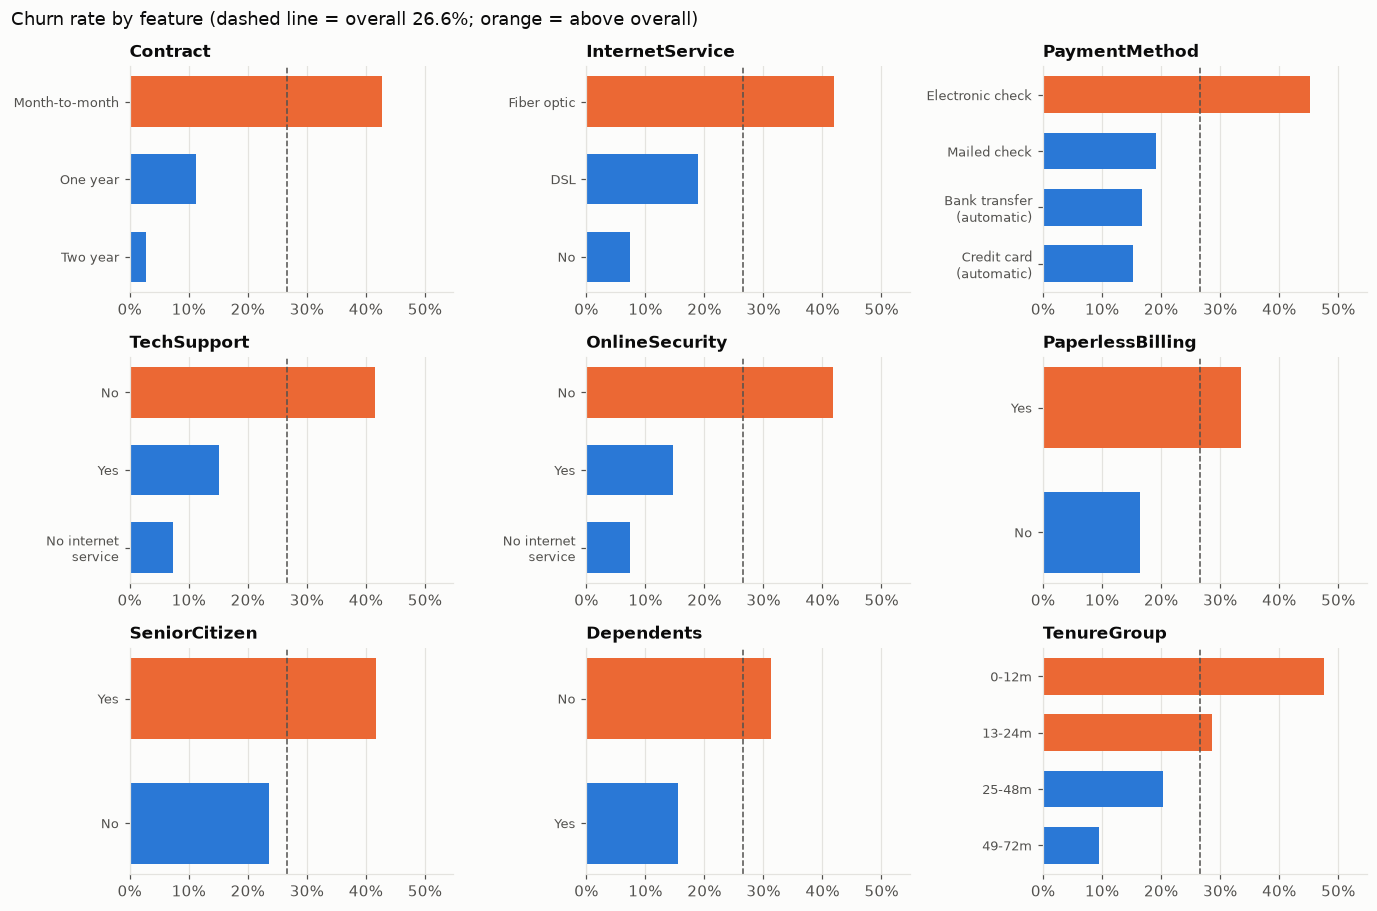

In [5]:
result = run(settings)
rates = analysis.churn_rate_by(result.customers, PROFILE_COLUMNS)
viz.plot_churn_rate_by_feature(rates, result.churn_rate);

In [6]:
rates.sort_values("churn_rate", ascending=False).head(10).style.format({"churn_rate": "{:.1%}"}).hide(axis="index")

feature,value,customers,churn_rate
TenureGroup,0-12m,2175,47.7%
PaymentMethod,Electronic check,2365,45.3%
Contract,Month-to-month,3875,42.7%
InternetService,Fiber optic,3096,41.9%
OnlineSecurity,No,3497,41.8%
SeniorCitizen,Yes,1142,41.7%
TechSupport,No,3472,41.6%
PaperlessBilling,Yes,4168,33.6%
Dependents,No,4933,31.3%
TenureGroup,13-24m,1024,28.7%


## 4. Biểu diễn dữ liệu dạng giao dịch

Apriori làm việc trên **giao dịch** (tập item). Mỗi khách hàng là một giao dịch, mỗi item có dạng `Thuộc_tính=Giá_trị`.

| Nhóm | Xử lý |
|---|---|
| Nhị phân & phân loại | Giữ nguyên giá trị (`Contract=Two year`, `Partner=Yes`, …) |
| `tenure` | Chia nhóm theo kỳ hợp đồng: `0-12m`, `13-24m`, `25-48m`, `49-72m` |
| `MonthlyCharges`, `TotalCharges` | Chia 3 phân vị đều: `Low`, `Medium`, `High` |
| `No internet service`, `No phone service` | Loại bỏ — đã được thể hiện qua `InternetService=No` / `PhoneService=No`, giữ lại sẽ sinh luật hiển nhiên |

In [7]:
for basket in result.transactions[:3]:
    print(sorted(basket), end="\n\n")
print(f"Transactions: {len(result.transactions):,} | Distinct items: {result.onehot.shape[1]}")

['Churn=No', 'Contract=Month-to-month', 'Dependents=No', 'DeviceProtection=No', 'InternetService=DSL', 'MonthlyCharges=Low', 'OnlineBackup=Yes', 'OnlineSecurity=No', 'PaperlessBilling=Yes', 'Partner=Yes', 'PaymentMethod=Electronic check', 'PhoneService=No', 'SeniorCitizen=No', 'StreamingMovies=No', 'StreamingTV=No', 'TechSupport=No', 'TenureGroup=0-12m', 'TotalCharges=Low', 'gender=Female']

['Churn=No', 'Contract=One year', 'Dependents=No', 'DeviceProtection=Yes', 'InternetService=DSL', 'MonthlyCharges=Medium', 'MultipleLines=No', 'OnlineBackup=No', 'OnlineSecurity=Yes', 'PaperlessBilling=No', 'Partner=No', 'PaymentMethod=Mailed check', 'PhoneService=Yes', 'SeniorCitizen=No', 'StreamingMovies=No', 'StreamingTV=No', 'TechSupport=No', 'TenureGroup=25-48m', 'TotalCharges=Medium', 'gender=Male']

['Churn=Yes', 'Contract=Month-to-month', 'Dependents=No', 'DeviceProtection=No', 'InternetService=DSL', 'MonthlyCharges=Medium', 'MultipleLines=No', 'OnlineBackup=Yes', 'OnlineSecurity=Yes', 'Pap

In [8]:
result.onehot.head()

,Churn=No,Churn=Yes,Contract=Month-to-month,Contract=One year,Contract=Two year,Dependents=No,Dependents=Yes,DeviceProtection=No,DeviceProtection=Yes,InternetService=DSL,...,TechSupport=Yes,TenureGroup=0-12m,TenureGroup=13-24m,TenureGroup=25-48m,TenureGroup=49-72m,TotalCharges=High,TotalCharges=Low,TotalCharges=Medium,gender=Female,gender=Male
0,True,False,True,False,False,True,False,True,False,True,...,False,True,False,False,False,False,True,False,True,False
1,True,False,False,True,False,True,False,False,True,True,...,False,False,False,True,False,False,False,True,False,True
2,False,True,True,False,False,True,False,True,False,True,...,False,True,False,False,False,False,True,False,False,True
3,True,False,False,True,False,True,False,False,True,True,...,True,False,False,True,False,False,False,True,False,True
4,False,True,True,False,False,True,False,True,False,False,...,False,True,False,False,False,False,True,False,True,False


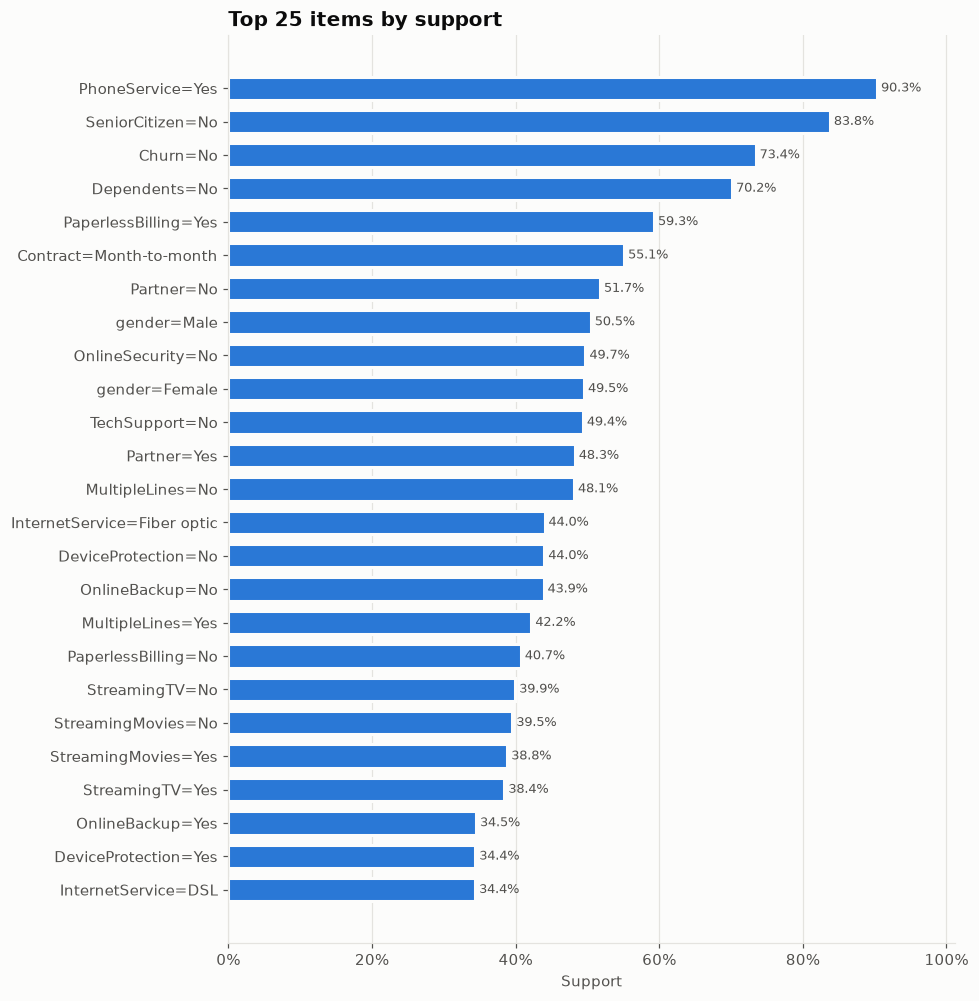

In [9]:
viz.plot_item_support(analysis.item_support(result.onehot), top_n=25);

## 5. Thuật toán Apriori

Cài đặt trong `src/telco_arm/apriori.py`:

1. **L₁**: đếm support từng item, giữ các item ≥ `min_support`.
2. **Sinh ứng viên Cₖ**: nối hai tập (k−1) có chung k−2 phần tử đầu (đã sắp xếp).
3. **Tỉa (Apriori property)**: loại ứng viên có tập con (k−1) không phổ biến.
4. **Đếm support** bằng phép AND vector bit của tập tiền tố và item cuối — không quét lại toàn bộ CSDL.
5. Lặp đến khi Lₖ rỗng hoặc đạt `max_len`.

Phần **hành vi dịch vụ** chỉ dùng item *có sử dụng* (loại `OnlineSecurity=No`, … và nhãn `Churn`) để luật phản ánh hành vi dùng dịch vụ thay vì sự vắng mặt dịch vụ.

In [10]:
behavior = usage_items(result.onehot, settings.features, exclude=settings.target_items)
itemsets = apriori(behavior, settings.mining.min_support, settings.mining.max_len)
display(analysis.itemset_length_summary(itemsets))
analysis.readable_itemsets(itemsets).query("length >= 3").head(10)

,length,count,max_support,mean_support
0,1,38,0.9033,0.3780
1,2,424,0.7557,0.1963
2,3,1262,0.4979,0.1514
3,4,1569,0.3477,0.1302


,support,itemsets,length
462,0.4979,"Dependents=No, PhoneService=Yes, SeniorCitizen=No",3
463,0.4245,"PaperlessBilling=Yes, PhoneService=Yes, SeniorCitizen=No",3
464,0.4199,"Dependents=No, Partner=No, PhoneService=Yes",3
465,0.3986,"Dependents=No, PaperlessBilling=Yes, PhoneService=Yes",3
466,0.3963,"Contract=Month-to-month, Dependents=No, PhoneService=Yes",3
467,0.3941,"Contract=Month-to-month, PhoneService=Yes, SeniorCitizen=No",3
468,0.3914,"Partner=No, PhoneService=Yes, SeniorCitizen=No",3
469,0.3867,"Dependents=No, Partner=No, SeniorCitizen=No",3
470,0.3815,"PhoneService=Yes, SeniorCitizen=No, gender=Male",3
471,0.3741,"PhoneService=Yes, SeniorCitizen=No, gender=Female",3


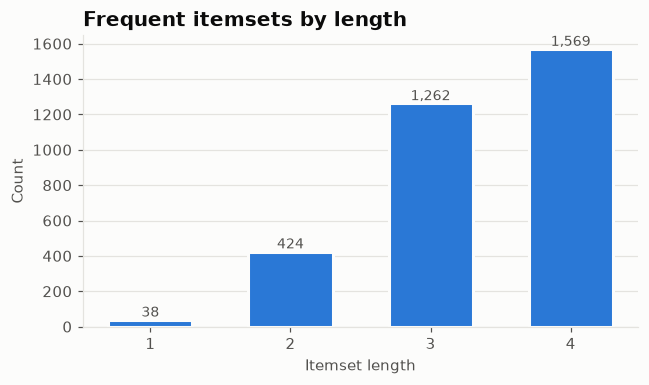

In [11]:
viz.plot_itemset_lengths(analysis.itemset_length_summary(itemsets));

### 5.1. Kiểm chứng tính đúng đắn với `mlxtend`

In [12]:
%%time
from mlxtend.frequent_patterns import apriori as mlxtend_apriori

reference = mlxtend_apriori(behavior, min_support=settings.mining.min_support,
                            use_colnames=True, max_len=settings.mining.max_len)
ours = dict(zip(itemsets["itemsets"], itemsets["support"].round(12)))
theirs = dict(zip(reference["itemsets"], reference["support"].round(12)))
print(f"Own: {len(ours):,} itemsets | mlxtend: {len(theirs):,} itemsets | identical: {ours == theirs}")

Own: 3,293 itemsets | mlxtend: 3,293 itemsets | identical: True
CPU times: total: 141 ms
Wall time: 163 ms


### 5.2. Độ nhạy theo ngưỡng `min_support`

,min_support,itemsets,rules,seconds
0,0.050,11358,13214,1.190
1,0.075,5898,7917,0.420
2,0.100,3293,4861,0.315
3,0.150,1085,1641,0.052
4,0.200,429,561,0.020
5,0.250,182,155,0.009
6,0.300,100,67,0.006


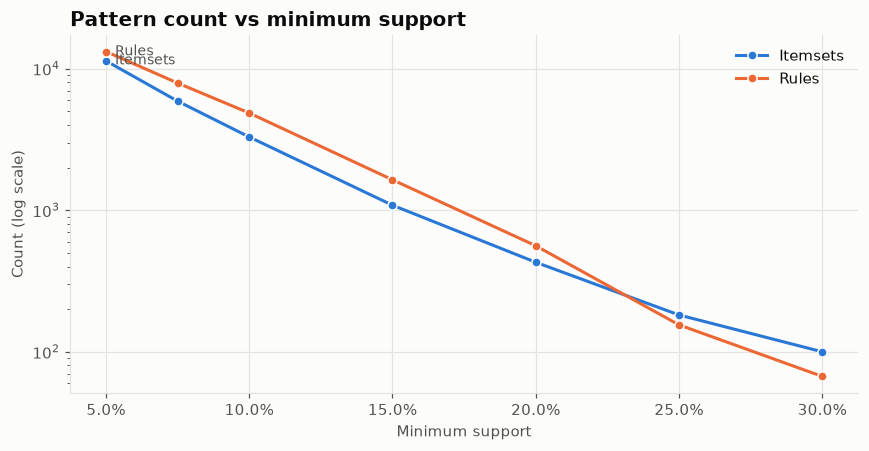

In [13]:
sensitivity = analysis.support_sensitivity(
    behavior, supports=[0.05, 0.075, 0.10, 0.15, 0.20, 0.25, 0.30],
    min_confidence=settings.mining.min_confidence, max_len=settings.mining.max_len,
)
display(sensitivity)
viz.plot_support_sensitivity(sensitivity);

Số tập phổ biến và số luật tăng theo hàm mũ khi giảm `min_support`. Ngưỡng **10%** (≈ 700 khách hàng) cân bằng giữa độ phủ và khả năng diễn giải.

## 6. Luật hành vi sử dụng dịch vụ

Đánh giá luật `X → Y`:
- **Support** = P(X ∪ Y) — mức độ phổ biến.
- **Confidence** = P(Y | X) — độ tin cậy.
- **Lift** = Confidence / P(Y) — > 1: X và Y xuất hiện cùng nhau nhiều hơn ngẫu nhiên.
- **Leverage** = P(X ∪ Y) − P(X)·P(Y); **Conviction** = (1 − P(Y)) / (1 − Confidence).

In [14]:
service_rules = generate_rules(itemsets, settings.mining.min_confidence, settings.mining.min_lift)
print(f"{len(service_rules):,} rules (confidence ≥ {settings.mining.min_confidence:.0%}, lift ≥ {settings.mining.min_lift})")
analysis.readable_rules(service_rules).head(15)

3,339 rules (confidence ≥ 70%, lift ≥ 1.2)


,rule,antecedents,consequents,antecedent_len,support,confidence,lift,leverage,conviction
0,"{Contract=Two year, TotalCharges=High} → {DeviceProtection=Yes, TenureGroup=49-72m}","Contract=Two year, TotalCharges=High","DeviceProtection=Yes, TenureGroup=49-72m",2,0.1001,0.7442,4.2859,0.0768,3.2303
1,"{InternetService=Fiber optic, TenureGroup=49-72m} → {MonthlyCharges=High, TotalCharges=High}","InternetService=Fiber optic, TenureGroup=49-72m","MonthlyCharges=High, TotalCharges=High",2,0.1340,0.9290,4.1769,0.1019,10.9510
2,"{MonthlyCharges=Low, Partner=Yes, PhoneService=Yes} → {InternetService=No}","MonthlyCharges=Low, Partner=Yes, PhoneService=Yes",InternetService=No,3,0.1042,0.8961,4.1456,0.0791,7.5434
3,"{MonthlyCharges=Low, PaperlessBilling=No, PhoneService=Yes} → {InternetService=No}","MonthlyCharges=Low, PaperlessBilling=No, PhoneService=Yes",InternetService=No,3,0.1529,0.8819,4.0798,0.1154,6.6355
4,"{InternetService=No} → {MonthlyCharges=Low, PaperlessBilling=No, PhoneService=Yes}",InternetService=No,"MonthlyCharges=Low, PaperlessBilling=No, PhoneService=Yes",1,0.1529,0.7072,4.0798,0.1154,2.8236
5,"{MonthlyCharges=High, TenureGroup=49-72m} → {InternetService=Fiber optic, TotalCharges=High}","MonthlyCharges=High, TenureGroup=49-72m","InternetService=Fiber optic, TotalCharges=High",2,0.1340,0.8618,3.9767,0.1003,5.6697
6,"{MonthlyCharges=Low, PaymentMethod=Mailed check, PhoneService=Yes} → {InternetService=No}","MonthlyCharges=Low, PaymentMethod=Mailed check, PhoneService=Yes",InternetService=No,3,0.1045,0.8566,3.9631,0.0781,5.4678
7,"{MonthlyCharges=Low, PhoneService=Yes, gender=Female} → {InternetService=No}","MonthlyCharges=Low, PhoneService=Yes, gender=Female",InternetService=No,3,0.1061,0.8373,3.8734,0.0787,4.8166
8,"{MonthlyCharges=Low, PhoneService=Yes, SeniorCitizen=No} → {InternetService=No}","MonthlyCharges=Low, PhoneService=Yes, SeniorCitizen=No",InternetService=No,3,0.2088,0.8346,3.8610,0.1547,4.7381
9,"{InternetService=No} → {MonthlyCharges=Low, PhoneService=Yes, SeniorCitizen=No}",InternetService=No,"MonthlyCharges=Low, PhoneService=Yes, SeniorCitizen=No",1,0.2088,0.9658,3.8610,0.1547,21.9189


In [15]:
addons = {item for item in SERVICE_ITEMS if not item.startswith(("Contract", "Payment", "Paperless", "Churn"))}
cross_sell = service_rules[
    service_rules["antecedents"].map(lambda s: s <= addons) & service_rules["consequents"].map(lambda s: s <= addons)
]
analysis.readable_rules(cross_sell).head(15)

,rule,antecedents,consequents,antecedent_len,support,confidence,lift,leverage,conviction
0,"{MultipleLines=Yes, StreamingTV=Yes} → {PhoneService=Yes, StreamingMovies=Yes}","MultipleLines=Yes, StreamingTV=Yes","PhoneService=Yes, StreamingMovies=Yes",2,0.1719,0.7671,2.2172,0.0944,2.8085
1,"{MultipleLines=Yes, StreamingMovies=Yes} → {PhoneService=Yes, StreamingTV=Yes}","MultipleLines=Yes, StreamingMovies=Yes","PhoneService=Yes, StreamingTV=Yes",2,0.1719,0.7599,2.2081,0.0941,2.7316
2,"{InternetService=Fiber optic, StreamingMovies=Yes} → {PhoneService=Yes, StreamingTV=Yes}","InternetService=Fiber optic, StreamingMovies=Yes","PhoneService=Yes, StreamingTV=Yes",2,0.1863,0.7481,2.1739,0.1006,2.6041
3,"{StreamingMovies=Yes, StreamingTV=Yes, TechSupport=Yes} → {DeviceProtection=Yes}","StreamingMovies=Yes, StreamingTV=Yes, TechSupport=Yes",DeviceProtection=Yes,3,0.1003,0.7468,2.1719,0.0541,2.5916
4,"{InternetService=Fiber optic, StreamingTV=Yes} → {PhoneService=Yes, StreamingMovies=Yes}","InternetService=Fiber optic, StreamingTV=Yes","PhoneService=Yes, StreamingMovies=Yes",2,0.1863,0.7486,2.1636,0.1002,2.6012
5,"{DeviceProtection=Yes, StreamingTV=Yes, TechSupport=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, StreamingTV=Yes, TechSupport=Yes",StreamingMovies=Yes,3,0.1003,0.8383,2.1585,0.0538,3.7822
6,"{DeviceProtection=Yes, MultipleLines=Yes, StreamingMovies=Yes} → {StreamingTV=Yes}","DeviceProtection=Yes, MultipleLines=Yes, StreamingMovies=Yes",StreamingTV=Yes,3,0.1173,0.8291,2.1571,0.0629,3.6032
7,"{DeviceProtection=Yes, InternetService=Fiber optic, StreamingMovies=Yes} → {StreamingTV=Yes}","DeviceProtection=Yes, InternetService=Fiber optic, StreamingMovies=Yes",StreamingTV=Yes,3,0.1139,0.8283,2.1550,0.0610,3.5861
8,"{DeviceProtection=Yes, MultipleLines=Yes, StreamingTV=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, MultipleLines=Yes, StreamingTV=Yes",StreamingMovies=Yes,3,0.1173,0.8350,2.1501,0.0628,3.7073
9,"{DeviceProtection=Yes, InternetService=Fiber optic, StreamingTV=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, InternetService=Fiber optic, StreamingTV=Yes",StreamingMovies=Yes,3,0.1139,0.8301,2.1373,0.0606,3.5989


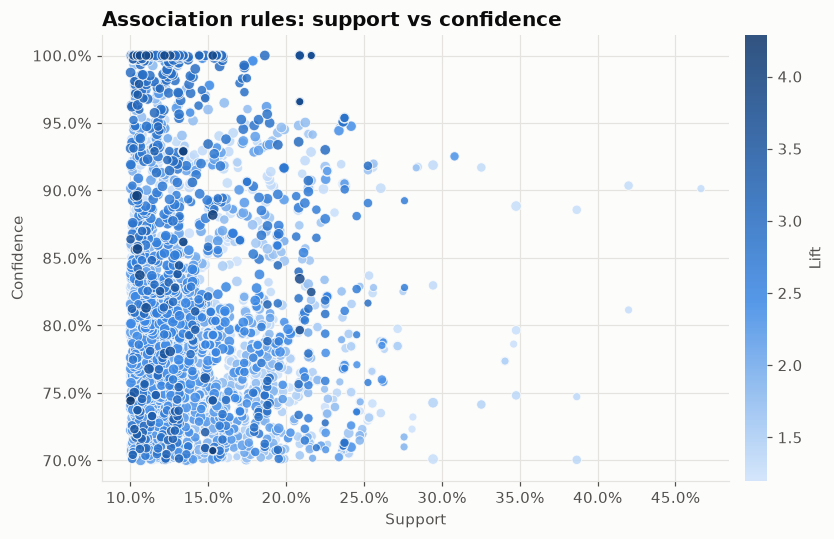

In [16]:
viz.plot_rules_scatter(service_rules);

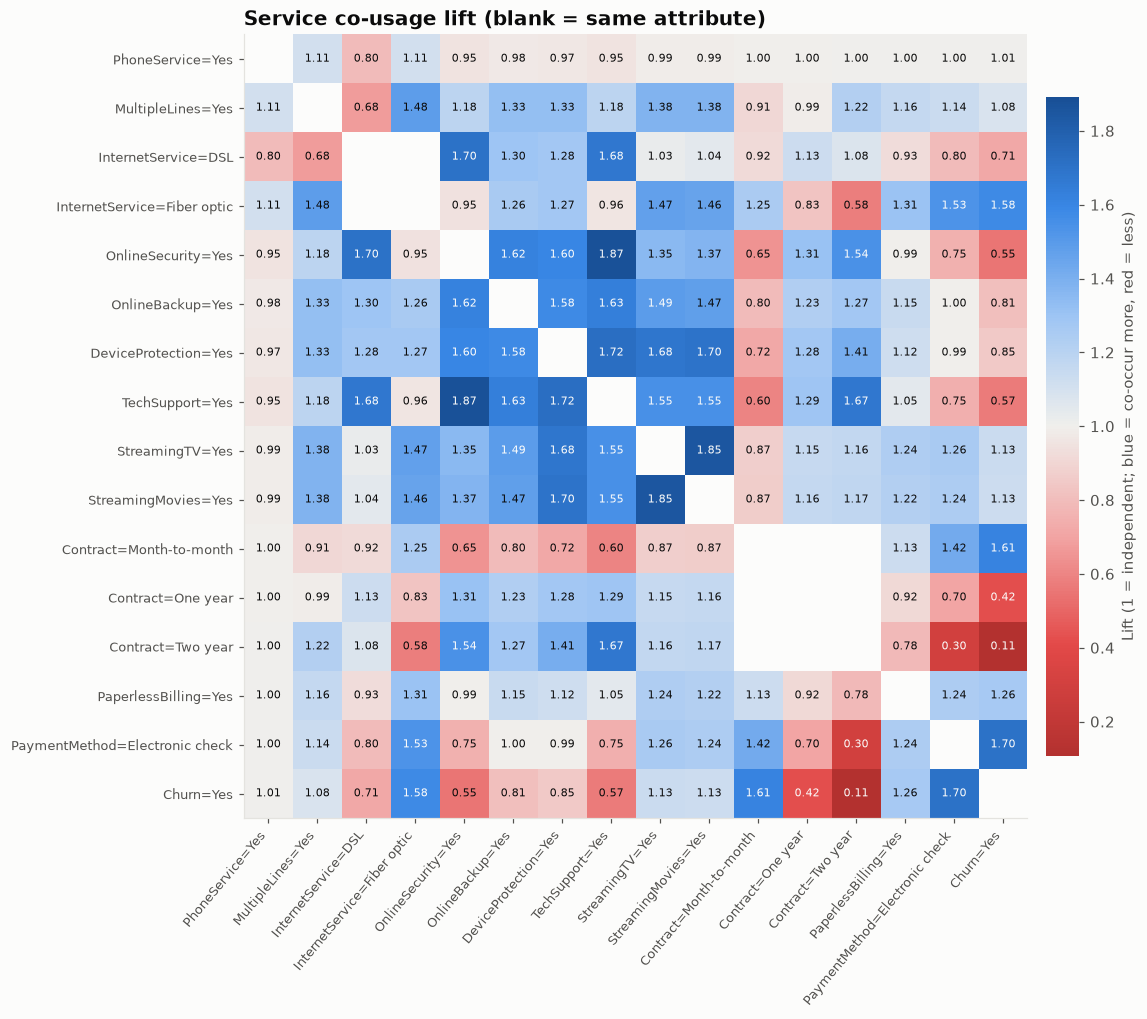

In [17]:
viz.plot_lift_matrix(analysis.pairwise_lift(result.onehot, SERVICE_ITEMS), title="Service co-usage lift");

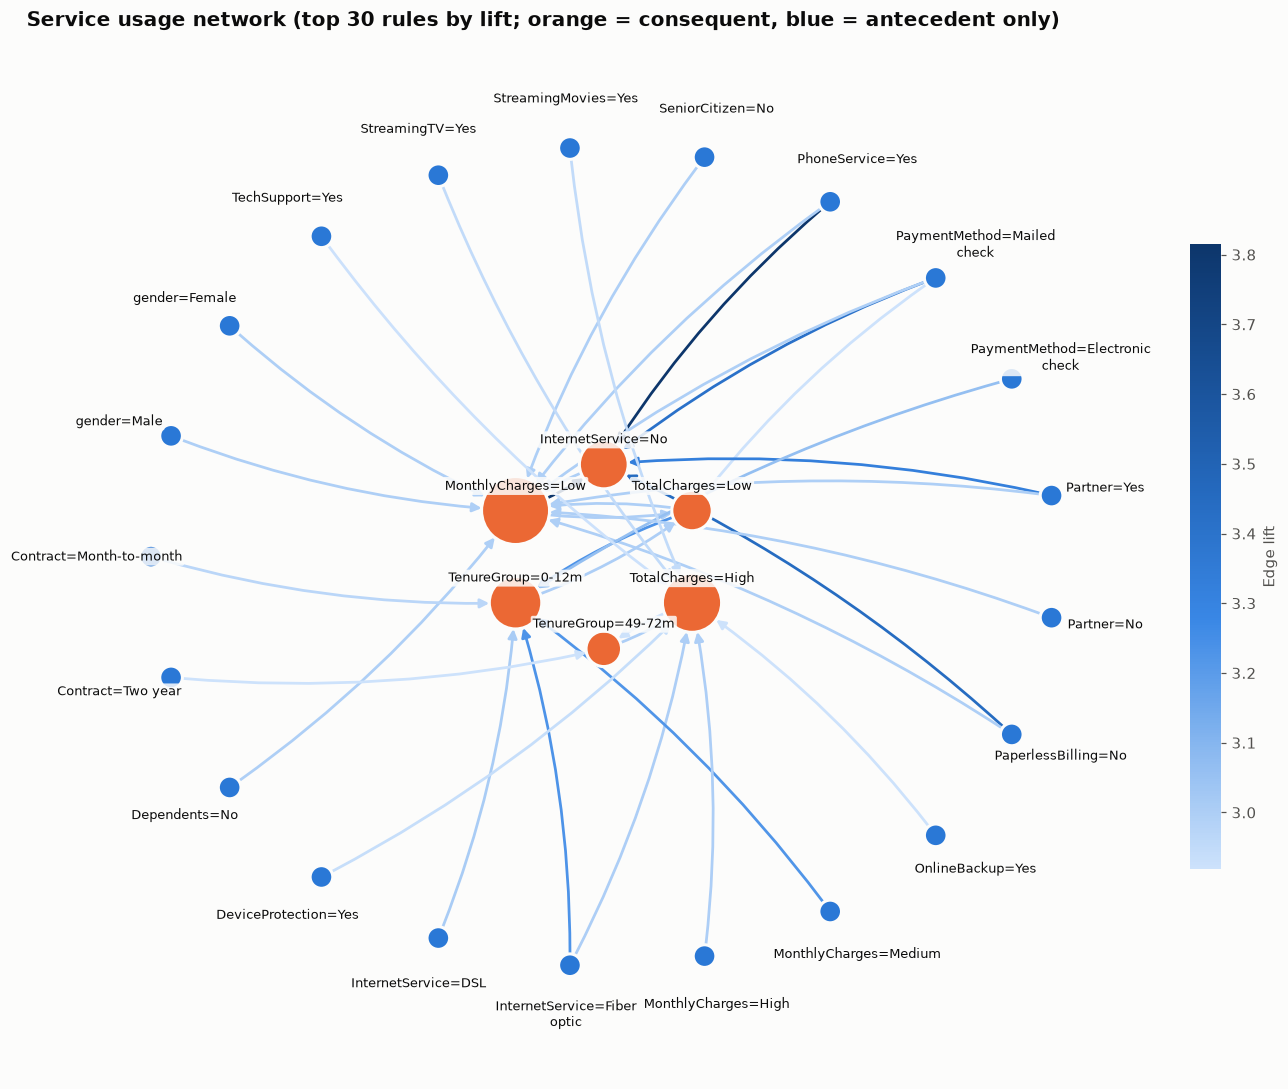

In [18]:
viz.plot_rule_network(service_rules[service_rules["antecedent_len"] <= 2], title="Service usage network");

## 7. Luật dẫn đến rời mạng (`→ Churn=Yes`)

Khách rời mạng chỉ chiếm ~26,6% nên cần `min_support` thấp hơn. Để tránh bùng nổ tổ hợp, áp dụng **Apriori có mục tiêu**:

- Chạy Apriori trên tập con khách hàng rời mạng với ngưỡng `min_support / P(Churn=Yes)` — tương đương `support(X ∪ {Churn=Yes}) ≥ min_support`.
- Tính `support(X)` trên toàn bộ dữ liệu để có confidence và lift.
- **Tỉa luật dư thừa**: chỉ giữ luật mà confidence vượt mọi luật con tổng quát hơn ít nhất `min_improvement` (2 điểm %).

In [19]:
churn_rules = result.churn_rules
print(f"{len(churn_rules):,} non-redundant churn rules | params: {settings.churn}")
analysis.readable_rules(churn_rules).head(15)

692 non-redundant churn rules | params: TargetParams(target='Churn=Yes', min_support=0.03, min_confidence=0.55, min_lift=2.0, max_len=5, min_improvement=0.02)


,rule,antecedents,consequents,antecedent_len,support,confidence,lift,leverage,conviction
0,"{Dependents=No, InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m} → {Churn=Yes}","Dependents=No, InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m",Churn=Yes,4,0.0330,0.7891,2.9690,0.0219,3.4816
1,"{MonthlyCharges=High, OnlineSecurity=No, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}","MonthlyCharges=High, OnlineSecurity=No, TechSupport=No, TenureGroup=0-12m",Churn=Yes,4,0.0310,0.7730,2.9086,0.0203,3.2351
2,"{InternetService=Fiber optic, StreamingMovies=Yes, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}","InternetService=Fiber optic, StreamingMovies=Yes, TechSupport=No, TenureGroup=0-12m",Churn=Yes,4,0.0316,0.7708,2.9002,0.0207,3.2038
3,"{MonthlyCharges=High, PaperlessBilling=Yes, TenureGroup=0-12m} → {Churn=Yes}","MonthlyCharges=High, PaperlessBilling=Yes, TenureGroup=0-12m",Churn=Yes,3,0.0334,0.7680,2.8895,0.0219,3.1644
4,"{InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m} → {Churn=Yes}","InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m",Churn=Yes,3,0.0368,0.7640,2.8745,0.0240,3.1112
5,"{InternetService=Fiber optic, MultipleLines=Yes, TenureGroup=0-12m} → {Churn=Yes}","InternetService=Fiber optic, MultipleLines=Yes, TenureGroup=0-12m",Churn=Yes,3,0.0407,0.7586,2.8543,0.0264,3.0417
6,"{MultipleLines=Yes, OnlineSecurity=No, PaperlessBilling=Yes, TenureGroup=0-12m} → {Churn=Yes}","MultipleLines=Yes, OnlineSecurity=No, PaperlessBilling=Yes, TenureGroup=0-12m",Churn=Yes,4,0.0350,0.7523,2.8305,0.0226,2.9641
7,"{InternetService=Fiber optic, StreamingMovies=Yes, TenureGroup=0-12m} → {Churn=Yes}","InternetService=Fiber optic, StreamingMovies=Yes, TenureGroup=0-12m",Churn=Yes,3,0.0356,0.7508,2.8247,0.0230,2.9457
8,"{InternetService=Fiber optic, PaperlessBilling=Yes, TotalCharges=Low} → {Churn=Yes}","InternetService=Fiber optic, PaperlessBilling=Yes, TotalCharges=Low",Churn=Yes,3,0.0593,0.7487,2.8168,0.0382,2.9211
9,"{MultipleLines=Yes, PaperlessBilling=Yes, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}","MultipleLines=Yes, PaperlessBilling=Yes, TechSupport=No, TenureGroup=0-12m",Churn=Yes,4,0.0348,0.7470,2.8104,0.0224,2.9015


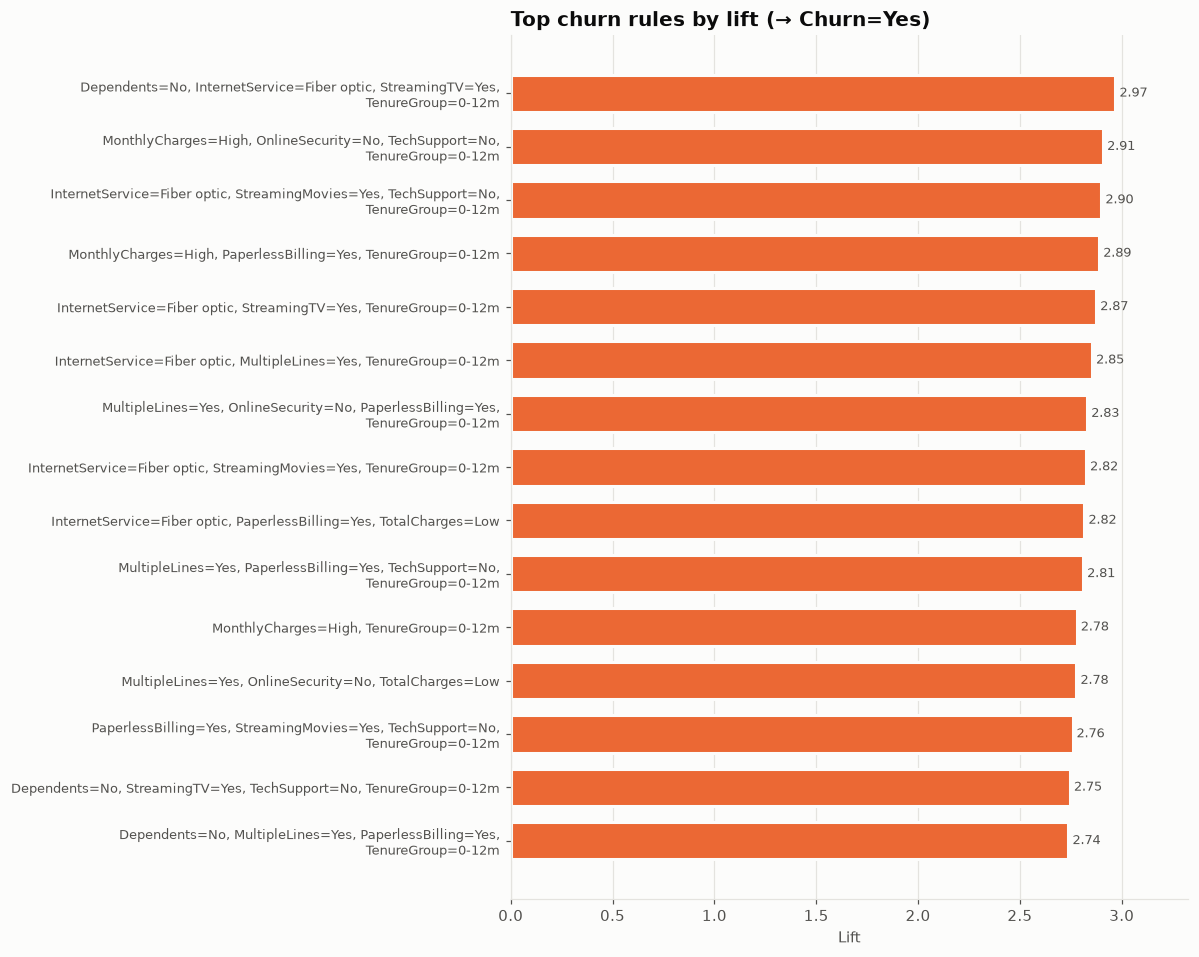

In [20]:
viz.plot_top_rules(churn_rules, title="Top churn rules by lift (→ Churn=Yes)",
                   color=viz.SERIES[1], show_consequent=False);

In [21]:
analysis.readable_rules(churn_rules.nlargest(10, "support"))[["rule", "support", "confidence", "lift"]]

,rule,support,confidence,lift
0,"{Contract=Month-to-month, InternetService=Fiber optic, TechSupport=No} → {Churn=Yes}",0.1469,0.5752,2.1640
1,"{Contract=Month-to-month, InternetService=Fiber optic, OnlineSecurity=No} → {Churn=Yes}",0.1466,0.5812,2.1866
2,"{InternetService=Fiber optic, OnlineSecurity=No, TechSupport=No} → {Churn=Yes}",0.1381,0.5501,2.0699
3,"{Contract=Month-to-month, InternetService=Fiber optic, PaperlessBilling=Yes} → {Churn=Yes}",0.1368,0.5696,2.1430
4,"{Contract=Month-to-month, OnlineSecurity=No, PaperlessBilling=Yes, TechSupport=No} → {Churn=Yes}",0.1340,0.5836,2.1959
5,"{Contract=Month-to-month, Dependents=No, PaperlessBilling=Yes, TechSupport=No} → {Churn=Yes}",0.1317,0.5657,2.1283
6,"{Contract=Month-to-month, InternetService=Fiber optic, OnlineSecurity=No, TechSupport=No} → {Churn=Yes}",0.1315,0.6070,2.2836
7,"{Contract=Month-to-month, Dependents=No, OnlineSecurity=No, PaperlessBilling=Yes} → {Churn=Yes}",0.1314,0.5676,2.1354
8,"{Contract=Month-to-month, OnlineBackup=No, OnlineSecurity=No, TechSupport=No} → {Churn=Yes}",0.1273,0.5759,2.1669
9,"{Contract=Month-to-month, PaymentMethod=Electronic check, TechSupport=No} → {Churn=Yes}",0.1249,0.5842,2.1979


### 7.1. Độ phủ thực tế của các luật churn trên tập khách hàng

In [22]:
coverage = analysis.rule_coverage(churn_rules, result.onehot, settings.churn.target, top_n=15)
coverage.style.format({"target_rate": "{:.1%}", "cumulative_recall": "{:.1%}"}).hide(axis="index")

rule,customers,target_hits,target_rate,cumulative_recall
"{Dependents=No, InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m} → {Churn=Yes}",294,232,78.9%,12.4%
"{MonthlyCharges=High, OnlineSecurity=No, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}",282,218,77.3%,15.9%
"{InternetService=Fiber optic, StreamingMovies=Yes, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}",288,222,77.1%,18.3%
"{MonthlyCharges=High, PaperlessBilling=Yes, TenureGroup=0-12m} → {Churn=Yes}",306,235,76.8%,19.1%
"{InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m} → {Churn=Yes}",339,259,76.4%,19.4%
"{InternetService=Fiber optic, MultipleLines=Yes, TenureGroup=0-12m} → {Churn=Yes}",377,286,75.9%,25.2%
"{MultipleLines=Yes, OnlineSecurity=No, PaperlessBilling=Yes, TenureGroup=0-12m} → {Churn=Yes}",327,246,75.2%,26.0%
"{InternetService=Fiber optic, StreamingMovies=Yes, TenureGroup=0-12m} → {Churn=Yes}",333,250,75.1%,26.1%
"{InternetService=Fiber optic, PaperlessBilling=Yes, TotalCharges=Low} → {Churn=Yes}",557,417,74.9%,32.5%
"{MultipleLines=Yes, PaperlessBilling=Yes, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}",328,245,74.7%,32.5%


In [23]:
analysis.item_frequency_in_rules(churn_rules).head(15).to_frame()

,rule_count
antecedents,
PaymentMethod=Electronic check,239
Contract=Month-to-month,239
TechSupport=No,212
OnlineSecurity=No,208
PaperlessBilling=Yes,207
OnlineBackup=No,184
InternetService=Fiber optic,162
Partner=No,145
DeviceProtection=No,132


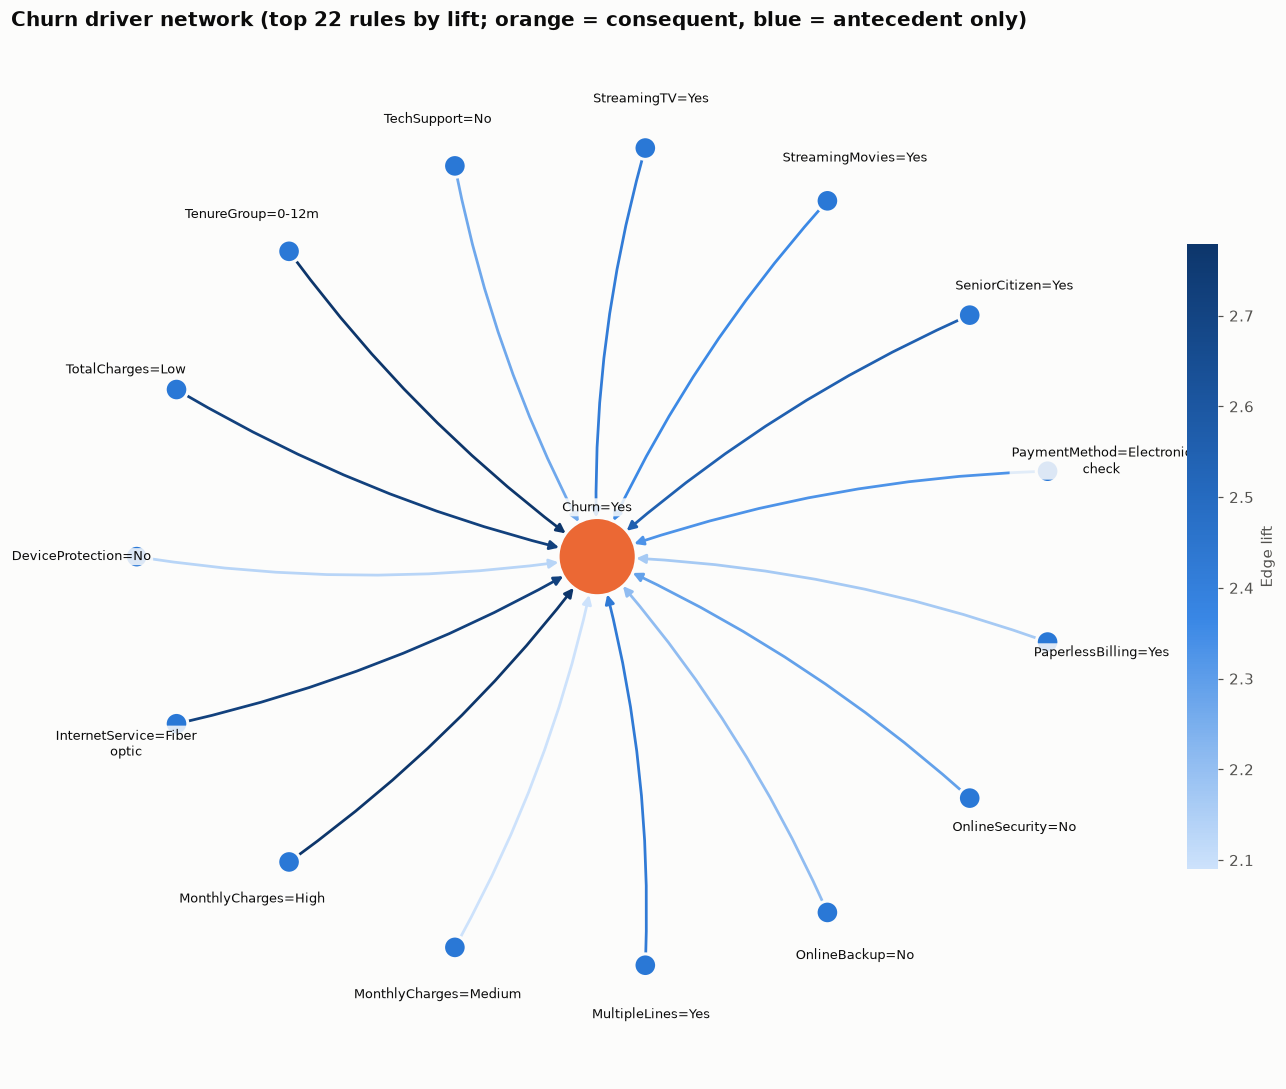

In [24]:
viz.plot_rule_network(churn_rules[churn_rules["antecedent_len"] <= 2], title="Churn driver network");

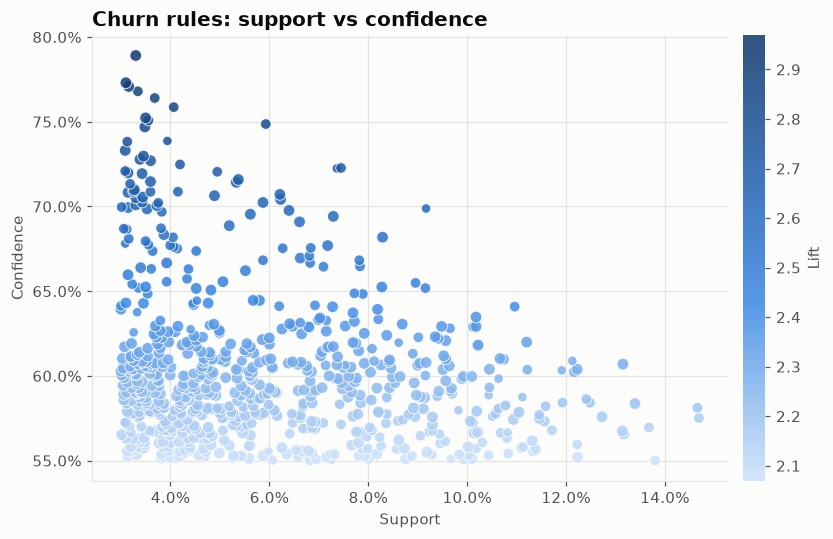

In [25]:
viz.plot_rules_scatter(churn_rules, title="Churn rules: support vs confidence");

## 8. Luật khách hàng trung thành (`→ Churn=No`)

In [26]:
retention_rules = result.retention_rules
print(f"{len(retention_rules):,} retention rules | params: {settings.retention}")
analysis.readable_rules(retention_rules)[["rule", "support", "confidence", "lift", "conviction"]]

24 retention rules | params: TargetParams(target='Churn=No', min_support=0.1, min_confidence=0.9, min_lift=1.2, max_len=5, min_improvement=0.02)


,rule,support,confidence,lift,conviction
0,"{MonthlyCharges=Low, PhoneService=Yes, TotalCharges=Medium} → {Churn=No}",0.1025,0.9743,1.3270,10.3516
1,{Contract=Two year} → {Churn=No},0.2328,0.9715,1.3232,9.3302
2,"{InternetService=No, Partner=Yes} → {Churn=No}",0.1001,0.9604,1.3081,6.7179
3,"{InternetService=DSL, TenureGroup=49-72m} → {Churn=No}",0.1072,0.9569,1.3032,6.1600
4,"{InternetService=DSL, TotalCharges=High} → {Churn=No}",0.1113,0.9549,1.3005,5.8904
5,"{MonthlyCharges=Low, TotalCharges=Medium} → {Churn=No}",0.1288,0.9447,1.2867,4.8092
6,"{PaperlessBilling=No, TenureGroup=49-72m} → {Churn=No}",0.1212,0.9446,1.2865,4.7948
7,"{Dependents=Yes, TenureGroup=49-72m} → {Churn=No}",0.1139,0.9390,1.2790,4.3599
8,"{MonthlyCharges=Low, Partner=Yes, PhoneService=Yes} → {Churn=No}",0.1091,0.9377,1.2771,4.2630
9,"{TechSupport=Yes, TenureGroup=49-72m} → {Churn=No}",0.1399,0.9345,1.2728,4.0561


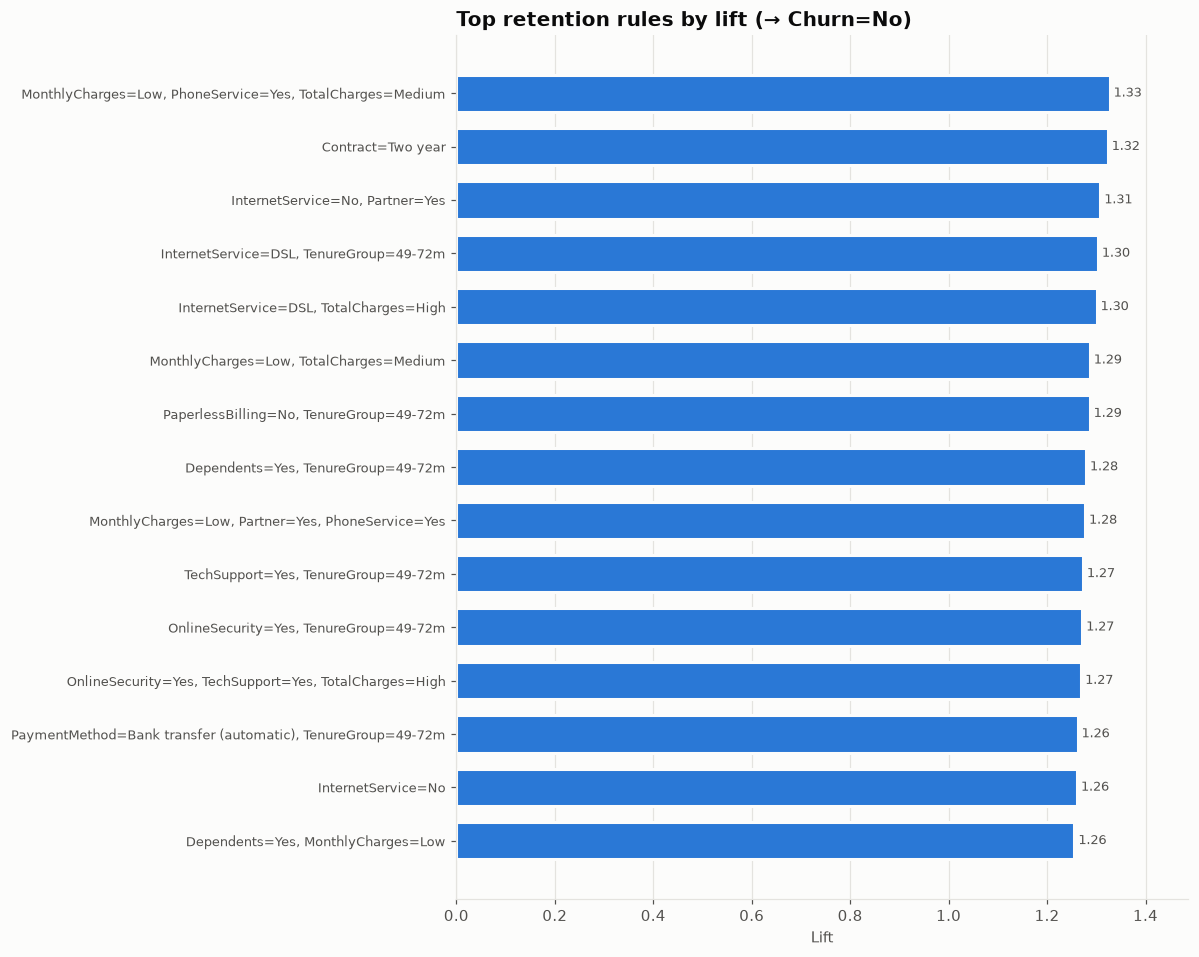

In [27]:
viz.plot_top_rules(retention_rules, title="Top retention rules by lift (→ Churn=No)", show_consequent=False);

## 9. Kết luận và khuyến nghị kinh doanh

### Hành vi sử dụng dịch vụ
- **StreamingTV ↔ StreamingMovies** (lift ≈ 1,85): hai dịch vụ giải trí gần như luôn đi cùng nhau → nên đóng gói thành một gói *Entertainment*.
- **Nhóm dịch vụ bảo vệ** `OnlineSecurity`, `TechSupport`, `DeviceProtection`, `OnlineBackup` có lift lẫn nhau 1,6–1,9 → bán chéo theo gói *Protection*.
- **Fiber optic** gắn với `MonthlyCharges=High`, `MultipleLines`, streaming; **DSL** gắn với `OnlineSecurity`, `TechSupport`.
- `Contract=Two year` đi cùng `TenureGroup=49-72m` và `TotalCharges=High` — tập khách hàng giá trị cao, gắn bó lâu.

### Yếu tố dẫn đến rời mạng
- Hồ sơ rủi ro điển hình: **khách mới (0–12 tháng) + Fiber optic + hợp đồng Month-to-month + không có OnlineSecurity/TechSupport + Electronic check / PaperlessBilling** → confidence 75–79%, lift ≈ 2,8–3,0 (gấp ~3 lần mức trung bình 26,6%).
- 10 luật churn mạnh nhất phủ khoảng **1/3 tổng số khách rời mạng**, tỷ lệ churn thực tế trong nhóm khớp 75–79%.
- Thiếu dịch vụ hỗ trợ kỹ thuật/bảo mật là yếu tố lặp lại nhiều nhất trong vế trái của luật churn.

### Yếu tố giữ chân
- `Contract=Two year` → `Churn=No` với confidence **97%**.
- Khách hàng thâm niên 49–72 tháng có `TechSupport=Yes`, `Dependents=Yes` hoặc dùng DSL đều có confidence giữ chân > 93%.

### Khuyến nghị
1. **Onboarding 12 tháng đầu** cho khách Fiber optic: tặng thử OnlineSecurity/TechSupport 3–6 tháng.
2. **Chuyển đổi hợp đồng**: ưu đãi nâng cấp từ Month-to-month lên 1–2 năm, ưu tiên nhóm khớp luật churn.
3. **Khuyến khích thanh toán tự động** (bank transfer/credit card) thay cho Electronic check.
4. **Gói combo** Entertainment và Protection dựa trên các luật đồng sử dụng có lift cao.
5. Dùng tập luật churn làm **quy tắc cảnh báo sớm** trong CRM — dễ diễn giải hơn mô hình hộp đen.

## 10. Xuất kết quả

In [28]:
tables = export_tables(result, settings.paths.tables_dir)
figures = export_figures(result, settings.paths.figures_dir)
pd.DataFrame({"file": [p.relative_to(PROJECT_ROOT).as_posix() for p in [*tables, *figures]]})

,file
0,outputs/tables/item_support.csv
1,outputs/tables/frequent_itemsets.csv
2,outputs/tables/service_rules.csv
3,outputs/tables/churn_rules.csv
4,outputs/tables/retention_rules.csv
5,outputs/tables/churn_rule_coverage.csv
6,outputs/tables/churn_rate_by_feature.csv
7,outputs/figures/01_item_support.png
8,outputs/figures/02_itemset_lengths.png
9,outputs/figures/03_churn_rate_by_feature.png
